# Фреймворки: TensorFlow, Keras, PyTorch
## Основы работы с моделями и данными

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 4. Глубокое обучение**

В этом файле мы изучаем интерфейсы инструментов: представление данных, создание модели, запуск обучения, получение ответов и сохранение небольшого обученного состояния. Устройство нейросетей, активации, оптимизаторы, backpropagation и регуляризация разобраны в предыдущих материалах; здесь не повторяем их теорию.

Материал предназначен для занятия и самостоятельного чтения. Заданий нет. Перед каждым блоком кода дано введение, после него — подробное объяснение конструкций Python, методов и результата. Формулы и математические выводы не используются.

Все наборы создаются внутри файла, примеры работают на CPU. Обучаются маленькие сети; модели и датасеты не скачиваются. В конце будут созданы небольшие файлы результатов в папке `12_результаты_фреймворки` рядом с местом выполнения ноутбука.

### Среда и порядок выполнения

**Все примеры выполнены в Python 3.13 с TensorFlow 2.21.0, Keras 3.15.1 и PyTorch 2.11.0. Keras использует backend TensorFlow. В файле сохранены выводы ячеек, таблицы и графики.**

В Jupyter выберите ядро **«Python — основы фреймворков ИИ»**. Оно связано с отдельной средой `%USERPROFILE%\.venvs\ai12`, например `C:\Users\user\.venvs\ai12`. Короткий путь помогает избежать ограничения длины путей Windows при установке TensorFlow. Для повторного выполнения выберите **Restart Kernel and Run All / «Перезапустить ядро и выполнить все ячейки»**. Ячейки связаны и выполняются сверху вниз.

Если нужно подготовить такую среду заново, из каталога курса запустите `powershell.exe -NoProfile -ExecutionPolicy Bypass -File .\12_Установить_фреймворки_короткий_путь.ps1 -EnvironmentPath "$env:USERPROFILE\.venvs\ai12"`. Это команда PowerShell: `-File` задаёт файл сценария, `-NoProfile` исключает пользовательские стартовые настройки, `-ExecutionPolicy Bypass` действует на этот запуск процесса. `-EnvironmentPath` задаёт короткий путь, а `$env:USERPROFILE` подставляет домашний каталог пользователя Windows. Скрипт скачивает библиотеки, проверяет их импорт и регистрирует учебное ядро. Добавление `-CheckOnly` запускает только предварительную проверку без установки.

В готовой среде интернет для всех примеров не нужен. Сам ноутбук не устанавливает пакеты. Первая ячейка печатает версии и фактический backend; итоговая сохраняет их вместе с описанием файлов результатов. Выбор backend делается до импорта Keras и требует нового процесса ядра.

## 1. Как связаны три названия

| Инструмент | Роль в материале | Основные интерфейсы |
|---|---|---|
| TensorFlow | Вычисления над тензорами и автоматическое получение градиентов; также backend для Keras | `tf.Tensor`, `tf.Variable`, `tf.GradientTape` |
| Keras 3 | Высокоуровневое описание модели и готовый цикл обучения поверх выбранного backend | `Sequential`, `Model`, `compile`, `fit`, `evaluate`, `predict` |
| PyTorch | Тензоры, модули сети и явно записанный цикл обучения | `torch.Tensor`, `nn.Module`, `DataLoader`, `state_dict` |

**Backend** — библиотека, выполняющая числовые операции модели Keras. Keras 3 может использовать TensorFlow, PyTorch или JAX. В этой теме JAX не рассматривается. В связке `tf.keras` высокоуровневый API доступен через TensorFlow; отдельный `import keras` позволяет явно работать с Keras 3 и выбранным backend.

В начале процесса выбирается один backend Keras. Менять переменную окружения после импорта недостаточно для безопасного переключения уже созданных объектов. Поэтому выбор делаем в первой ячейке, а для другого варианта перезапускаем ядро.

Выберем TensorFlow как вычислительную библиотеку Keras **до импорта фреймворков**. Настройки окружения действуют в текущем процессе: используем CPU и небольшое число потоков. Затем подключим инструменты и выведем версии, backend и путь интерпретатора, чтобы проверить среду запуска.

In [1]:
import os
import sys
import json
from pathlib import Path

os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib
import torch
import tensorflow as tf
import keras

from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display
from sklearn.datasets import make_moons
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.set_default_device('cpu')
torch.set_num_threads(1)
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
tensorflow_examples_executed = False

print('Python:', sys.version.split()[0])
print('Keras:', keras.__version__, '| backend:', keras.backend.backend())
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__, '| Pandas:', pd.__version__)
print('Matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)
print('TensorFlow:', tf.__version__)
print('Интерпретатор:', sys.executable)

Python: 3.13.13
Keras: 3.15.1 | backend: tensorflow
PyTorch: 2.11.0+xpu
NumPy: 2.4.6 | Pandas: 2.3.3
Matplotlib: 3.10.9 | scikit-learn: 1.8.0
TensorFlow: 2.21.0
Интерпретатор: C:\Users\user\.venvs\ai12\Scripts\python.exe


**Разбор кода и среды.**

- `import` подключает модуль, `from ... import ...` — отдельные инструменты, `as` даёт короткое имя. `tensorflow as tf` и `torch` подключают вычислительные библиотеки, `keras` — высокоуровневый API. `os` работает с окружением процесса, `sys` — со сведениями Python, `json` понадобится для текстового описания результатов, `Path` — для путей к файлам. NumPy, Pandas и Matplotlib служат массивам, таблицам и рисункам; scikit-learn — подготовке и оценке, `joblib` — сохранению подготовки.
- `os.environ[...] = ...` задаёт строковую переменную текущего процесса. `KERAS_BACKEND='tensorflow'` выбирает backend до `import keras`. `CUDA_VISIBLE_DEVICES='-1'` отключает выбор CUDA GPU. Переменные с `THREADS` ограничивают потоки TensorFlow; `TF_ENABLE_ONEDNN_OPTS='0'` отключает дополнительные оптимизации oneDNN для этого небольшого учебного запуска. `TF_CPP_MIN_LOG_LEVEL='1'` уменьшает информационный вывод TensorFlow, сохраняя сообщения об ошибках и предупреждения.
- `torch.set_default_device('cpu')` и `torch.set_num_threads(1)` задают CPU и один поток PyTorch. `pd.set_option(...)` управляет видом таблиц. `plt.rcParams[...]` настраивает шрифт с кириллицей и плотность рисунков. Присваивание через квадратные скобки меняет настройку с указанным именем.
- `tensorflow_examples_executed = False` создаёт начальный статус примеров TensorFlow. Он станет `True` после выполнения кода с переменной и градиентом. `False` и `True` — логические значения «нет» и «да».
- `print(...)` выводит значения. `sys.version.split()[0]` делит строку версии на части и берёт первую, `sys.executable` показывает путь интерпретатора, `.__version__` читает версии пакетов. `keras.backend.backend()` сообщает фактическую вычислительную библиотеку Keras.

В сохранённом выводе backend равен `tensorflow`. Значит, примеры Keras ниже используют TensorFlow, а отдельные примеры PyTorch — собственные тензоры и модули PyTorch. Все три инструмента подключены в одном учебном ядре.

## 2. Общие данные для примеров API

Обе полноценные модели будут решать одну небольшую бинарную задачу по двум числовым сигналам. Используем общие обучающую и валидационную части и одно правило подготовки. Это позволяет сопоставить действия API. Результаты не являются сравнением производительности фреймворков: начальные веса и детали обработки в разных реализациях могут отличаться.

Создадим 240 искусственных объектов и отложим четверть для валидации. Приведём признаки к сопоставимому масштабу по обучающим данным и сохраним дробный тип `float32`. Ответы сделаем столбцом: один объект — один бинарный ответ.

In [2]:
feature_names = ['Сигнал 1', 'Сигнал 2']
feature_values, labels = make_moons(n_samples=240, noise=0.18, random_state=31)
X_train_raw, X_valid_raw, y_train_values, y_valid_values = train_test_split(
    feature_values, labels, test_size=0.25, stratify=labels, random_state=15
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_valid = scaler.transform(X_valid_raw).astype(np.float32)
y_train = y_train_values.astype(np.float32).reshape(-1, 1)
y_valid = y_valid_values.astype(np.float32).reshape(-1, 1)

display(pd.DataFrame(X_train[:5], columns=feature_names))
print('Обучение:', X_train.shape, y_train.shape)
print('Валидация:', X_valid.shape, y_valid.shape)

,Сигнал 1,Сигнал 2
0,0.5423,-1.7417
1,-0.0311,-0.9402
2,1.2307,0.2869
3,1.1288,-0.0737
4,0.6150,-1.1363


Обучение: (180, 2) (180, 1)
Валидация: (60, 2) (60, 1)


**Разбор кода и данных.**

- `feature_names` — список имён в нужном порядке. `make_moons(...)` создаёт признаки и метки двух изогнутых групп. `n_samples` задаёт число объектов, `noise` — разброс, `random_state` — воспроизводимость.
- `train_test_split(...)` согласованно делит признаки и ответы. Четыре результата распределяются по четырём переменным. `test_size=0.25` выделяет четверть, `stratify=labels` учитывает доли классов, второй `random_state` фиксирует разбиение.
- `StandardScaler()` создаёт подготовку; `fit_transform(...)` изучает её на обучении и преобразует его, `transform(...)` применяет сохранённое правило к валидации. Теория подготовки уже была ранее.
- `.astype(np.float32)` задаёт дробный тип NumPy, согласованный с примерами слоёв. `.reshape(-1, 1)` делает один столбец, автоматически определяя число строк вместо `-1`. Это форма данных, а не изменение ответов.
- `[:5]` выбирает первые пять строк; `pd.DataFrame(..., columns=...)` и `display(...)` показывают их. `.shape` содержит размерности, `print(...)` выводит формы.

Получились 180 обучающих и 60 валидационных объектов с двумя признаками. Масштабирование не изучало валидационные строки. В дальнейшем признаки и ответы не смешиваются в один вход модели.

Покажем, как один массив NumPy превращается в тензор Keras выбранного backend и тензор PyTorch. Для передачи данных между таблицей и моделью важны форма, тип и порядок признаков. Новую модель здесь не обучаем.

In [3]:
numpy_sample = X_train[:3]
keras_sample = keras.ops.convert_to_tensor(numpy_sample, dtype='float32')
torch_sample = torch.from_numpy(numpy_sample)
display(pd.DataFrame(keras.ops.convert_to_numpy(keras_sample), columns=feature_names))
print('Keras: форма и тип:', tuple(keras_sample.shape), keras_sample.dtype)
print('PyTorch: форма, тип, устройство:', tuple(torch_sample.shape), torch_sample.dtype, torch_sample.device)

,Сигнал 1,Сигнал 2
0,0.5423,-1.7417
1,-0.0311,-0.9402
2,1.2307,0.2869


Keras: форма и тип: (3, 2) <dtype: 'float32'>
PyTorch: форма, тип, устройство: (3, 2) torch.float32 cpu


**Разбор кода и представлений.**

- `X_train[:3]` выбирает первые три объекта. `keras.ops.convert_to_tensor(..., dtype='float32')` создаёт тензор средствами API Keras; его конкретная реализация зависит от backend. `keras.ops.convert_to_numpy(...)` возвращает числа в формате NumPy для вывода.
- `torch.from_numpy(...)` создаёт тензор CPU, который может разделять память с исходным массивом NumPy. Здесь мы ничего в нём не меняем. Для независимой копии потребовалось бы явное копирование; в данных примерах представления используются для чтения и обучения весов.
- `.shape` сообщает форму, `tuple(...)` готовит размерности к выводу. `.dtype` показывает тип чисел, `.device` — устройство PyTorch.
- `pd.DataFrame(...)`, `display(...)` и `print(...)` выводят общие значения и сведения о представлении.

В этом запуске Keras использует TensorFlow: `keras_sample` представлен его тензором. `torch_sample` — тензор PyTorch с теми же исходными числами. Совпадение данных не делает эти объекты одним типом; для передачи чисел между интерфейсами здесь явно используется NumPy.

## 3. TensorFlow: тензор и переменная

`tf.Tensor` хранит данные вычисления. `tf.Variable` хранит изменяемое состояние, например веса. `tf.GradientTape` записывает связи операций для получения градиентов. Здесь изучаем названия и интерфейс; механизм обратного распространения уже разбирался.

Сначала создадим тензор, затем выполним один шаг изменения переменной. Полный высокоуровневый цикл обучения с TensorFlow представлен далее через Keras.

Создадим тензор TensorFlow из тех же трёх объектов и явно выберем CPU. Выведем его форму и тип, а значения вернём в NumPy для таблицы. Так можно проследить переход от подготовленных данных к объекту фреймворка.

In [4]:
with tf.device('/CPU:0'):
    tensorflow_sample = tf.constant(numpy_sample, dtype=tf.float32)
print('TensorFlow:', tf.__version__)
print('Форма:', tuple(tensorflow_sample.shape), '| тип:', tensorflow_sample.dtype)
display(pd.DataFrame(tensorflow_sample.numpy(), columns=feature_names))

TensorFlow: 2.21.0
Форма: (3, 2) | тип: <dtype: 'float32'>


,Сигнал 1,Сигнал 2
0,0.5423,-1.7417
1,-0.0311,-0.9402
2,1.2307,0.2869


**Разбор кода и тензора.**

- Имя `tf` было задано при `import tensorflow as tf`. Запись `with tf.device('/CPU:0'):` создаёт контекст выбора устройства для вложенных операций. Двоеточие начинает блок, отступ показывает его границы. `/CPU:0` обозначает первый CPU в обозначениях TensorFlow.
- `tf.constant(numpy_sample, dtype=tf.float32)` создаёт тензор с дробными числами заданного типа. Имя `tensorflow_sample` сохраняет ссылку на полученный объект. В этом примере у него нет методов изменения веса, используемых далее у `Variable`.
- `.shape` сообщает размерности, `tuple(...)` превращает их в кортеж для вывода, `.dtype` показывает тип. `.numpy()` возвращает значения как массив NumPy.
- `pd.DataFrame(..., columns=feature_names)` задаёт подписи двух столбцов, `display(...)` показывает таблицу, `print(...)` выводит сведения о библиотеке и форме.

Получен тензор формы `(3, 2)`: три объекта и два признака. Его значения совпадают с выбранными строками общего набора. Это выполненные операции TensorFlow.

Покажем интерфейсы `Variable` и `GradientTape` на трёх обучающих строках. Создадим два изменяемых веса, получим выход и потерю, вычислим градиент и сделаем один демонстрационный шаг. В таблице сравним состояние до и после; теория обучения здесь не повторяется.

In [5]:
with tf.device('/CPU:0'):
    tf_features = tf.constant(X_train[:3], dtype=tf.float32)
    tf_targets = tf.constant(y_train[:3], dtype=tf.float32)
    tf_weights = tf.Variable([[0.0], [0.0]], dtype=tf.float32)
    tf_weights_before = tf_weights.numpy().copy()
    with tf.GradientTape() as tape:
        tf_logits = tf.matmul(tf_features, tf_weights)
        tf_loss = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=tf_targets, logits=tf_logits))
    tf_gradient = tape.gradient(tf_loss, tf_weights)
    tf_weights.assign_sub(0.1 * tf_gradient)
display(pd.DataFrame({
    'Вес до шага': tf_weights_before.ravel(),
    'Градиент': tf_gradient.numpy().ravel(),
    'Вес после шага': tf_weights.numpy().ravel(),
}, index=feature_names))
tensorflow_examples_executed = True

,Вес до шага,Градиент,Вес после шага
Сигнал 1,0.0,-0.2903,0.0290
Сигнал 2,0.0,0.3992,-0.0399


**Разбор кода и изменения переменной.**

- В контексте `tf.device('/CPU:0')` вызовы `tf.constant(...)` создают признаки и ответы из срезов `[:3]`, то есть первых трёх строк. `tf.Variable([[0.0], [0.0]], dtype=tf.float32)` создаёт два изменяемых веса в столбце. Вложенные списки задают форму `(2, 1)`. `.numpy().copy()` делает независимый снимок исходных значений.
- `with tf.GradientTape() as tape:` записывает операции внутри блока и даёт контексту имя `tape`. Он автоматически отслеживает обучаемую `tf.Variable`, использованную в вычислении потери. Вложенные отступы отделяют запись операций от остальных действий.
- `tf.matmul(tf_features, tf_weights)` получает один логит для каждой строки. Библиотечная `tf.nn.sigmoid_cross_entropy_with_logits(labels=..., logits=...)` принимает правильные ответы и логиты; имена параметров показывают роль аргументов. `tf.reduce_mean(...)` сводит значения потерь к одному числу.
- `tape.gradient(tf_loss, tf_weights)` возвращает градиент потери по указанной переменной. Сам вызов градиента веса не меняет. `tf_weights.assign_sub(0.1 * tf_gradient)` отдельно уменьшает переменную на переданное изменение. `0.1` задаёт размер демонстрационного шага; полноценный оптимизатор далее создаётся через Keras.
- `.ravel()` превращает столбцы значений в одномерные массивы. `pd.DataFrame({...}, index=feature_names)` собирает словарь столбцов и подписывает строки именами признаков, `display(...)` показывает таблицу. `tensorflow_examples_executed = True` отмечает завершение реальных вычислений.

В столбце «Вес до шага» стоят нули. В столбце «Градиент» показан результат `GradientTape`, а «Вес после шага» содержит состояние после `assign_sub`. Один такой шаг демонстрирует работу API; полноценное обучение ниже выполняет много шагов по всем обучающим пакетам.

В выполненном примере градиенты для двух весов равны примерно -0,2903 и 0,3992. После шага вместо нулей получены 0,0290 и -0,0399. Эти значения показаны в таблице непосредственно после реального вычисления TensorFlow.

## 4. Keras: готовый цикл работы с моделью

### Создание и настройка

В Keras описание сети, настройка обучения и обучение — отдельные действия. `Sequential` задаёт цепочку слоёв. `compile` выбирает правило обучения, потерю и показатели. `fit` получает данные и запускает цикл. После этого `evaluate` вычисляет показатели, а `predict` возвращает выходы модели.

В данном примере последний слой возвращает **логит**, а не готовую вероятность. Это согласовано с `BinaryCrossentropy(from_logits=True)`. Теория выбора выхода и потери разобрана ранее; здесь важно правильно передать настройку API.

Создадим сеть с двумя входами, восемью скрытыми нейронами ReLU и одним логитом. Явный `Input` позволяет заранее построить модель и увидеть формы и число параметров. Начальное состояние фиксируем для повторяемости этого опыта.

In [6]:
keras.utils.set_random_seed(17)
keras_model = keras.Sequential([
    keras.Input(shape=(2,), name='signals'),
    keras.layers.Dense(8, activation='relu', name='hidden'),
    keras.layers.Dense(1, name='logit'),
], name='course_model')
keras_model.summary()

Model: "course_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden (Dense)                  │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33 (132.00 B)

 Trainable params: 33 (132.00 B)

 Non-trainable params: 0 (0.00 B)

**Разбор кода и структуры.**

- `keras.utils.set_random_seed(17)` задаёт случайное начальное состояние средствами Keras. Это помогает повторить один и тот же опыт; одинаковое число seed в разных библиотеках не гарантирует одинаковые начальные веса.
- `keras.Sequential([...], name=...)` создаёт последовательную модель из списка. `keras.Input(shape=(2,), ...)` описывает два признака одного объекта; размер пакета в `shape` не включён. `(2,)` — кортеж из одного числа: запятая отличает его от просто числа в скобках.
- `keras.layers.Dense(8, activation='relu', ...)` создаёт полносвязный скрытый слой. `Dense(1, ...)` без отдельной выходной активации выдаёт один логит. `name` задаёт читаемые имена для вывода и сохранённой структуры.
- `.summary()` показывает слои, формы и количество параметров. Значение `None` в размерности пакета означает, что число объектов не зафиксировано. Модель поддержит разные размеры входных пакетов с теми же двумя признаками.

В сети 33 обучаемых числа. Создание и вывод структуры ещё не обучили её. Тензоры с данными в этот код не передавались.

Настроим обучение через `compile`. Метрика бинарной точности будет сравнивать логит с нулём, поскольку выход модели не преобразован в вероятность. Поэтому явно зададим `threshold=0.0`; обычный порог 0,5 относился бы к другой шкале выхода.

In [7]:
keras_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.03),
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy', threshold=0.0)],
    jit_compile=False,
)
print('Настройка обучения выполнена. Backend:', keras.backend.backend())

Настройка обучения выполнена. Backend: tensorflow


**Разбор кода и настройки.**

- `.compile(...)` связывает модель с настройками, но не получает обучающие объекты. `keras.optimizers.Adam(learning_rate=0.03)` создаёт оптимизатор; смысл оптимизатора и шага уже изучался.
- `keras.losses.BinaryCrossentropy(from_logits=True)` сообщает, что в потерю поступает исходный логит. `True` — логическое «да». Нужная внутренняя обработка выполняется самой функцией потерь.
- `metrics=[...]` задаёт список отчётных показателей. `keras.metrics.BinaryAccuracy(...)` получает имя `accuracy` и порог нулевого логита. Настройка согласована с нашей моделью; формула метрики здесь не повторяется.
- `jit_compile=False` оставляет обычный режим выполнения без отдельной JIT-компиляции. Компиляция кода не является целью этого вводного примера. `False` означает «нет».
- `print(...)` и `keras.backend.backend()` показывают, с какой вычислительной библиотекой настроена модель.

Следующий шаг — передать данные в `fit`. Название метода `compile` не означает, что веса уже подобраны или что обязательно включён ускоренный компилятор.

В этом запуске TensorFlow вывел предупреждение об отсутствии поддержки GPU в обычной Windows. Для данного примера используется CPU, поэтому сообщение не препятствует обучению. Настройка `jit_compile=False` также не требует отдельной XLA-компиляции. Это сообщение о возможностях среды, а не ошибка настройки модели.

Запустим 80 эпох с пакетами по 16 объектов. Валидационные данные передадим явно; готовый цикл Keras организует обучение и проверку. Вместо длинного журнала каждого пакета сохраним объект истории и покажем несколько строк.

In [8]:
keras_history = keras_model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    epochs=80, batch_size=16, verbose=0,
)
keras_history_table = pd.DataFrame(keras_history.history)
keras_history_table.index = range(1, len(keras_history_table) + 1)
keras_history_table.index.name = 'Эпоха'
display(keras_history_table.iloc[[0, 19, 39, 79]])

,accuracy,loss,val_accuracy,val_loss
Эпоха,,,,
1,0.7556,0.4911,0.7833,0.4196
20,0.9778,0.0807,0.9500,0.1251
40,0.9889,0.0454,0.9667,0.0863
80,0.9944,0.0294,0.9667,0.0947


**Разбор кода и истории.**

- `.fit(X_train, y_train, ...)` получает признаки и ответы. `validation_data=(X_valid, y_valid)` — кортеж отдельной проверочной части. Данные не смешиваются с обучающими строками для подбора весов.
- `epochs=80` задаёт число полных проходов по обучающим объектам, `batch_size=16` — размер порции обновления. `verbose=0` выключает подробную печать процесса, но история и все вычисления сохраняются.
- Возвращённый объект `keras_history` содержит словарь `.history` со списками показателей по эпохам. `pd.DataFrame(...)` делает их столбцами.
- `range(1, len(...) + 1)` создаёт номера эпох с единицы, присваивание `.index` задаёт их как индекс. `.index.name` подписывает его. `.iloc[[0, 19, 39, 79]]` выбирает строки по позициям, то есть эпохи 1, 20, 40, 80. `display(...)` показывает фрагмент.

Ключи `loss`, `accuracy` относятся к обучению; `val_loss`, `val_accuracy` — к переданной валидации. Здесь фиксировано число эпох; выбор «лучшей» эпохи и критерии ранней остановки в этот пример не входят.

В сохранённом запуске Keras с backend TensorFlow после 80 эпох получил обучающую потерю около 0,0294 и валидационную около 0,0947. Значения взяты из реальной истории `fit`; при другой версии или начальном состоянии они могут отличаться.

Отдельно вызовем `evaluate` на валидации. Метод возвращает показатели из `compile`, а не прогноз для каждой строки. Попросим словарь, чтобы имена показателей оставались явными и не зависели от запоминания их порядка.

In [9]:
keras_evaluation = keras_model.evaluate(X_valid, y_valid, verbose=0, return_dict=True)
display(pd.DataFrame([keras_evaluation], index=['Keras: валидация']))

,accuracy,loss
Keras: валидация,0.9667,0.0947


**Разбор кода и результата.**

- `.evaluate(...)` применяет обученную модель к признакам, сравнивает с ответами и считает заданные показатели. `verbose=0` убирает подробный вывод, `return_dict=True` возвращает словарь с именами.
- Квадратные скобки `[keras_evaluation]` создают список из одной строки для `pd.DataFrame(...)`. `index=[...]` даёт ей имя, `display(...)` показывает результат.

Оценка не выполняет дополнительный подбор весов. Полученные `loss` и `accuracy` относятся к текущему обученному состоянию и этим 60 объектам, а не к произвольным будущим данным.

На этой валидации accuracy около 0,9667: правильно определены 58 из 60 классов. Потеря около 0,0947. Это показатели одного обученного состояния; `evaluate` не выбирает новую архитектуру и не выполняет дополнительное обучение.

Получим выходы через `predict` и свяжем их с первыми пятью фактическими ответами. Поскольку модель выдаёт логиты, оценки класса 1 покажем отдельным преобразованием Keras. Для класса используем то же правило нулевого порога, что в отчётной метрике.

In [10]:
keras_logits = keras_model.predict(X_valid, verbose=0)
keras_probabilities = keras.ops.convert_to_numpy(keras.ops.sigmoid(keras_logits)).ravel()
keras_predictions = (keras_logits.ravel() > 0.0).astype(int)
keras_prediction_table = pd.DataFrame({
    'Факт': y_valid_values,
    'Логит': keras_logits.ravel(),
    'Оценка класса 1': keras_probabilities,
    'Предсказанный класс': keras_predictions,
})
display(keras_prediction_table.head())

,Факт,Логит,Оценка класса 1,Предсказанный класс
0,1,14.7000,1.0000,1
1,1,23.4345,1.0000,1
2,1,2.0672,0.8877,1
3,1,5.1997,0.9945,1
4,0,-6.8844,0.0010,0


**Разбор кода и ответа.**

- `.predict(...)` возвращает выход модели на каждую строку. Он не получает правильные ответы. `verbose=0` убирает подробную печать; здесь результат — массив NumPy формы `(60, 1)`.
- `keras.ops.sigmoid(...)` преобразует логиты в оценки, `keras.ops.convert_to_numpy(...)` получает массив для отчёта. Эти операции остаются в API Keras, без привязки к конкретному типу тензора backend.
- `.ravel()` разворачивает один столбец в одномерный массив. Сравнение `> 0.0` создаёт логические решения, `.astype(int)` переводит их в классы 0 и 1. Нулевой логит в выбранном правиле относится к классу 0.
- `pd.DataFrame(...)` соединяет факты и выходы в одинаковом порядке; `head()` выбирает первые пять строк, `display(...)` показывает их.

Выход `predict` зависит от последнего слоя. Здесь это логит, поэтому готовые классы и оценки получены явно. В другой модели с выходной sigmoid сам `predict` возвращал бы уже преобразованные значения. Формат нужно читать по описанию конкретной модели.

Прочитаем веса Keras через `get_weights`. Эта функция возвращает числовые массивы, а не готовые ответы модели. По формам массивов можно проверить соответствие описанным слоям, не выводя все отдельные числа.

In [11]:
keras_weight_arrays = keras_model.get_weights()
weight_rows = []
for number, values in enumerate(keras_weight_arrays, start=1):
    weight_rows.append({
        'Массив': number,
        'Форма': str(values.shape),
        'Чисел': values.size,
    })
display(pd.DataFrame(weight_rows).set_index('Массив'))
print('Всего параметров модели:', keras_model.count_params())

,Форма,Чисел
Массив,,
1,"(2, 8)",16
2,"(8,)",8
3,"(8, 1)",8
4,"(1,)",1


Всего параметров модели: 33


**Разбор кода и форм.**

- `.get_weights()` возвращает список массивов NumPy с текущими весами. `enumerate(..., start=1)` добавляет порядковый номер, цикл распаковывает его и массив в переменные.
- `.shape` показывает размерности, `str(...)` превращает их в текст, `.size` считает числа в массиве. `.append({...})` накапливает строки, `pd.DataFrame(...)`, `.set_index(...)` и `display(...)` формируют таблицу.
- `.count_params()` сообщает общее число параметров, `print(...)` выводит его.

У двух Dense-слоёв четыре массива: веса перехода `(2, 8)`, смещения `(8,)`, веса выхода `(8, 1)` и смещение `(1,)`. Эти формы помогают читать API Keras. В PyTorch ориентация матрицы Linear будет другой; одинаковая задача не требует одинакового хранения массивов.

### Functional API: явное соединение слоёв

`Sequential` удобен для одной цепочки. **Functional API** описывает входы и связи явно: объект слоя вызывается на символическом входе и создаёт символический выход. `keras.Model` объединяет их в модель. Такой способ также позволяет описывать более сложные связи, но здесь оставим ту же простую цепочку для чтения синтаксиса.

Опишем ту же архитектуру функционально и скопируем в неё уже обученные веса. Дополнительно обучать модель не будем. Проверим совпадение выходов с исходной моделью на первых пяти проверочных объектах; совпасть должны формы слоёв и порядок весов. Для небольшого массива напрямую вызовем модель в режиме получения ответа и преобразуем тензор в NumPy.

In [12]:
functional_inputs = keras.Input(shape=(2,), name='signals_functional')
functional_hidden = keras.layers.Dense(8, activation='relu')(functional_inputs)
functional_outputs = keras.layers.Dense(1)(functional_hidden)
functional_model = keras.Model(inputs=functional_inputs, outputs=functional_outputs, name='functional_course_model')
functional_model.set_weights(keras_model.get_weights())
functional_logits = keras.ops.convert_to_numpy(functional_model(X_valid[:5], training=False))
print('Форма входа модели:', functional_model.input_shape)
print('Форма выхода модели:', functional_model.output_shape)
print('Выходы совпадают:', np.allclose(functional_logits, keras_logits[:5], atol=0.000001))

Форма входа модели: (None, 2)
Форма выхода модели: (None, 1)
Выходы совпадают: True


**Разбор кода и результата.**

- `keras.Input(...)` создаёт символическое описание входа, а не массив объектов. В записи `keras.layers.Dense(...)(functional_inputs)` сначала создаётся слой, затем он вызывается на символическом входе. Вторые круглые скобки задают связь с предыдущим элементом.
- `keras.Model(inputs=..., outputs=...)` собирает модель по указанным входу и выходу. Числовой расчёт произойдёт при подаче реальных данных.
- `.get_weights()` получает обученные массивы исходной модели, `.set_weights(...)` копирует их в совместимую по структуре модель. Это перенос чисел, а не запуск `fit`. Состояние оптимизатора в этом опыте не копируется.
- `functional_model(X_valid[:5], training=False)` напрямую получает выходы для первых пяти строк. Модель вызывается круглыми скобками как функция; `training=False` выбирает режим получения ответа. `keras.ops.convert_to_numpy(...)` переводит выходной тензор TensorFlow в NumPy для сравнения. `.input_shape` и `.output_shape` описывают формы. `np.allclose(..., atol=0.000001)` проверяет близость чисел с заданным абсолютным допуском. `print(...)` показывает результаты.

При одинаковых связях, активациях и весах два способа описания этой сети дают одинаковые выходы с точностью вычислений. Functional API не означает автоматическое улучшение качества: это способ задать структуру.

Этот функциональный вариант не был скомпилирован для обучения. Для прямого получения выхода на уже заданных весах достаточно структуры и самих весов; compile подключает настройки потерь, оптимизатора и отчётных метрик для соответствующих методов. Проверка совпадения выходов в данном выполнении вывела True.

Для небольшого массива, помещающегося в один пакет, Keras рекомендует прямой вызов `model(..., training=False)`. Метод `predict` удобен для обработки набора пакетами и уже показан выше. Оба интерфейса описаны в [справке Keras](https://keras.io/api/models/model_training_apis/#predict-method).

### Сохранение и восстановление Keras

Файл `.keras` хранит описание модели и её веса, а для скомпилированной модели — также относящиеся к ней настройки и состояние обучения. Подготовка исходных признаков из scikit-learn в саму модель не входила, поэтому сохраним её отдельно. Для новых сырых данных нужны и сеть, и то же правило подготовки, и порядок полей.

Здесь сохраняются только собственные маленькие результаты учебного примера. При повторном полном выполнении файлы с этими именами будут обновлены.

Создадим папку результатов, сохраним обученную модель Keras и объект подготовки. `Path` позволяет строить пути без ручного соединения разделителей Windows. Все файлы относятся к этому примеру; внешний файл с моделью не скачивается.

In [13]:
artifact_dir = Path('12_результаты_фреймворки')
artifact_dir.mkdir(parents=True, exist_ok=True)
keras_path = artifact_dir / 'модель_keras.keras'
scaler_path = artifact_dir / 'подготовка_признаков.joblib'
keras_model.save(keras_path)
joblib.dump(scaler, scaler_path)
print('Модель Keras:', keras_path.resolve())
print('Подготовка:', scaler_path.resolve())

Модель Keras: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\12_результаты_фреймворки\модель_keras.keras
Подготовка: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\12_результаты_фреймворки\подготовка_признаков.joblib


**Разбор кода и файлов.**

- `Path(...)` создаёт объект пути. Относительная папка строится от рабочего каталога ядра; в подготовленном выполнении это каталог курса. `.mkdir(parents=True, exist_ok=True)` создаёт её вместе с нужными родительскими папками и допускает уже существующую папку.
- Оператор `/` у `Path` добавляет имя файла к каталогу; здесь это построение пути, а не деление чисел. `keras_model.save(...)` записывает модель в формате `.keras`.
- `joblib.dump(scaler, scaler_path)` сохраняет отдельный объект `StandardScaler`, уже изучивший обучающую часть. `joblib` используется только для собственной подготовки этого ноутбука.
- `.resolve()` получает абсолютный путь, `print(...)` показывает созданные файлы.

В файле Keras ожидается вход уже с двумя подготовленными признаками. Отдельный файл подготовки понадобится, когда исходные значения поступят снова. Сохранение сети не означает автоматического включения в неё всех предшествующих действий Pandas или scikit-learn.

Загрузим созданную модель и проверим, что её выходы на валидации сохранились. Это проверка восстановления собственного файла, а не новое обучение или новая оценка архитектуры. Полная валидационная таблица уже получена выше. Передадим весь небольшой массив напрямую с `training=False` и вернём значения в NumPy для сравнения.

In [14]:
loaded_keras_model = keras.models.load_model(keras_path)
loaded_keras_logits = keras.ops.convert_to_numpy(loaded_keras_model(X_valid, training=False))
print('Параметров в загруженной модели:', loaded_keras_model.count_params())
print('Логиты после загрузки близки:', np.allclose(keras_logits, loaded_keras_logits, atol=0.000001))

Параметров в загруженной модели: 33
Логиты после загрузки близки: True


**Разбор кода и восстановления.**

- `keras.models.load_model(...)` читает созданный `.keras` и возвращает модель. Её структуру не требуется описывать заново для этого формата.
- `loaded_keras_model(X_valid, training=False)` напрямую применяет загруженную сеть к тому же подготовленному массиву в режиме получения ответа. `keras.ops.convert_to_numpy(...)` возвращает значения тензора как массив NumPy.
- `.count_params()` проверяет размер модели. `np.allclose(...)` сравнивает числовые логиты с учётом вычислительной точности, `atol` задаёт абсолютный допуск. `print(...)` сообщает итог.

Совпадение означает, что данный цикл сохранения и загрузки воспроизвёл выходы сети в текущей среде. Для сырых исходных полей отдельно восстановим подготовку в конце материала.

## 5. PyTorch: данные, модуль и явный цикл

В предыдущих файлах готовые слои PyTorch использовались для изучения обучения и регуляризации. Теперь добавим типичную организацию кода фреймворка: `Dataset` объединяет данные объектов, `DataLoader` выдаёт пакеты, собственный класс `nn.Module` описывает модель, а цикл вызывает её на пакетах.

Будет та же задача и схема сети с восемью скрытыми нейронами и логитом. Здесь сравниваем интерфейсы, а не проверяем, какая библиотека «лучше» на одном примере. Веса разных реализаций могут инициализироваться по разным правилам.

Объединим подготовленные признаки и ответы в `TensorDataset`, затем создадим `DataLoader` с пакетами по 16 объектов. Перемешивание относится только к обучающей части. Покажем формы одного пакета; для обучения ниже создадим загрузчик заново с исходным состоянием генератора.

In [15]:
torch_train_features = torch.from_numpy(X_train)
torch_train_targets = torch.from_numpy(y_train)
torch_valid_features = torch.from_numpy(X_valid)
torch_valid_targets = torch.from_numpy(y_valid)
torch_dataset = TensorDataset(torch_train_features, torch_train_targets)
preview_loader = DataLoader(
    torch_dataset, batch_size=16, shuffle=True,
    generator=torch.Generator().manual_seed(45), num_workers=0,
)
preview_features, preview_targets = next(iter(preview_loader))
print('Объектов в Dataset:', len(torch_dataset))
print('Пакет признаков:', tuple(preview_features.shape))
print('Пакет ответов:', tuple(preview_targets.shape))

Объектов в Dataset: 180
Пакет признаков: (16, 2)
Пакет ответов: (16, 1)


**Разбор кода и загрузчика.**

- `torch.from_numpy(...)` создаёт тензорное представление массивов. `TensorDataset(...)` объединяет признаки и ответы по одинаковой позиции строки: элемент набора содержит пару для одного объекта.
- `DataLoader(...)` организует выдачу пакетов. `batch_size=16` задаёт размер, `shuffle=True` включает перемешивание обучения, `num_workers=0` оставляет выдачу данных в текущем процессе без запуска дополнительных рабочих процессов.
- `torch.Generator().manual_seed(45)` создаёт отдельный воспроизводимый генератор порядка. Его состояние меняется при переборе пакетов. Поэтому демонстрационный загрузчик не будем затем незаметно использовать как будто он ещё не выдавал строки.
- `iter(preview_loader)` получает перебор, `next(...)` берёт первый пакет. Запись с двумя переменными слева распаковывает признаки и ответы.
- `len(...)`, `.shape`, `tuple(...)` и `print(...)` выводят число объектов и формы.

Весь набор не обязан помещаться в один пакет. У этих 180 объектов последний пакет будет меньше 16; слоёв Batch Normalization в данном примере нет. Валидацию далее применяем отдельным подготовленным тензором, без перемешивания фактов относительно предсказаний.

Опишем собственный класс модели PyTorch. Внутри он использует знакомую `nn.Sequential`, а метод `forward` задаёт получение выхода. Такой класс явно фиксирует структуру, которая позднее понадобится при восстановлении `state_dict`.

In [16]:
class CourseNetwork(nn.Module):
    def __init__(self, input_features=2, hidden_units=8):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_features, hidden_units),
            nn.ReLU(),
            nn.Linear(hidden_units, 1),
        )

    def forward(self, features):
        return self.layers(features)

torch.manual_seed(17)
torch_model = CourseNetwork()
print(torch_model)
print('Параметров:', sum(parameter.numel() for parameter in torch_model.parameters()))

CourseNetwork(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)
Параметров: 33


**Разбор класса и объекта.**

- `class CourseNetwork(nn.Module):` создаёт собственный класс на основе `nn.Module`. Класс описывает устройство объектов, `CourseNetwork()` ниже создаёт конкретный экземпляр.
- `def __init__(self, ...)` — метод, автоматически выполняемый при создании. `self` обозначает текущий объект; значения `input_features=2`, `hidden_units=8` можно передать иначе при создании. `super().__init__()` инициализирует часть родительского `nn.Module`, в том числе механизмы регистрации слоёв.
- `self.layers = ...` сохраняет слои как атрибут объекта. `nn.Sequential`, `nn.Linear` и `nn.ReLU` задают ту же последовательность размеров. PyTorch хранит веса Linear в порядке «выходы, входы», поэтому первая матрица имеет форму `(8, 2)`, в отличие от `(2, 8)` у Dense Keras.
- `def forward(self, features):` описывает прямое получение ответа; `return self.layers(features)` возвращает выход цепочки. Вызывать модель будем как `torch_model(features)`: `nn.Module` организует вызов `forward` сам.
- `torch.manual_seed(17)` задаёт начальное случайное состояние PyTorch. `.parameters()` перечисляет параметры, `.numel()` считает числа, `sum(... for ... in ...)` суммирует их. `print(...)` выводит структуру и размер.

Получилось 33 параметра, как у схемы Keras. Равное число не доказывает равенства исходных весов или порядка обновлений. Компоновка массива и API модели — отдельные свойства фреймворка.

Создадим новый загрузчик и выполним 80 эпох. Здесь цикл записан явно: PyTorch выдаёт пакеты, а код вызывает подготовленную модель и знакомые действия обучения. В историю запишем среднюю потерю обучающих пакетов и отдельную потерю валидации после эпохи.

In [17]:
train_loader = DataLoader(
    torch_dataset, batch_size=16, shuffle=True,
    generator=torch.Generator().manual_seed(45), num_workers=0,
)
torch_optimizer = torch.optim.Adam(torch_model.parameters(), lr=0.03)
torch_criterion = nn.BCEWithLogitsLoss()
torch_history_rows = []

for epoch in range(1, 81):
    torch_model.train()
    total_loss = 0.0
    for batch_features, batch_targets in train_loader:
        torch_optimizer.zero_grad(set_to_none=True)
        batch_logits = torch_model(batch_features)
        batch_loss = torch_criterion(batch_logits, batch_targets)
        batch_loss.backward()
        torch_optimizer.step()
        total_loss += batch_loss.item() * len(batch_features)

    torch_model.eval()
    with torch.no_grad():
        epoch_valid_loss = torch_criterion(torch_model(torch_valid_features), torch_valid_targets).item()
    torch_history_rows.append({
        'Эпоха': epoch,
        'loss': total_loss / len(torch_dataset),
        'val_loss': epoch_valid_loss,
    })

torch_history_table = pd.DataFrame(torch_history_rows).set_index('Эпоха')
display(torch_history_table.loc[[1, 20, 40, 80]])

,loss,val_loss
Эпоха,,
1,0.5940,0.4966
20,0.2095,0.3334
40,0.1899,0.2982
80,0.1654,0.3482


**Разбор кода и цикла.**

- Новый `DataLoader(...)` начинает порядок пакетов с отдельного исходного генератора. `torch.optim.Adam(torch_model.parameters(), lr=0.03)` сохраняет один оптимизатор на всё обучение. `nn.BCEWithLogitsLoss()` согласован с выходным логитом модели.
- `torch.Generator().manual_seed(45)` создаёт воспроизводимый генератор именно этого загрузчика. Его состояние сохраняется при следующих переборах, поэтому `shuffle=True` может давать новый порядок в каждой эпохе.
- `range(1, 81)` задаёт 80 эпох. `.train()` включает обучающий режим. Внутренний цикл `for batch_features, batch_targets in train_loader` получает пары уже собранных пакетов без ручных срезов массива.
- `zero_grad`, вызов `torch_model(...)`, `torch_criterion(...)`, `backward` и `step` выполняют изученный шаг. Здесь их назначение не переопределяется новым классом модели.
- `.item()` извлекает потерю пакета для отчёта. `total_loss += ...` означает накопление: к прежнему значению добавляется вклад с учётом `len(batch_features)`. Деление на `len(torch_dataset)` даёт отчётное среднее с учётом меньшего последнего пакета.
- `.eval()` выбирает проверочное поведение, `torch.no_grad()` отдельно отключает запись графа для валидационного вызова. `.append({...})` добавляет историю, `pd.DataFrame(...)`, `.set_index(...)`, `.loc[[...]]` и `display(...)` показывают нужные эпохи.

В Keras последовательность обучения была внутри `fit`; здесь её видит и организует автор программы. Это различие интерфейса и ответственности за код. Оно не означает, что ручной цикл всегда даёт более высокое качество.

Получим валидационные выходы PyTorch в `eval` и `no_grad`. Покажем первые строки и F1 по готовым классам. Используем то же правило выбора по знаку логита, что и в примере Keras, а оценки sigmoid выведем отдельно.

In [18]:
torch_model.eval()
with torch.no_grad():
    torch_logits = torch_model(torch_valid_features)
    torch_validation_loss = torch_criterion(torch_logits, torch_valid_targets).item()
    torch_probabilities = torch.sigmoid(torch_logits).squeeze(1).numpy()
    torch_predictions = (torch_logits.squeeze(1).numpy() > 0.0).astype(int)
torch_prediction_table = pd.DataFrame({
    'Факт': y_valid_values,
    'Оценка класса 1': torch_probabilities,
    'Предсказанный класс': torch_predictions,
})
display(torch_prediction_table.head())
print('Валидационная потеря:', round(torch_validation_loss, 4))
print('F1 класса 1:', round(f1_score(y_valid_values, torch_predictions, zero_division=0), 4))

,Факт,Оценка класса 1,Предсказанный класс
0,1,1.0000,1
1,1,1.0000,1
2,1,0.2963,0
3,1,0.3255,0
4,0,0.3310,0


Валидационная потеря: 0.3482
F1 класса 1: 0.8621


**Разбор кода и результата.**

- `.eval()` задаёт режим модели, `torch.no_grad()` отключает запись графа. `torch_model(...)` выдаёт логиты, `torch_criterion(...)` сопоставляет их с фактами; `.item()` читает потерю.
- `torch.sigmoid(...)` получает оценки, `.squeeze(1)` убирает единичный столбец, `.numpy()` готовит числа для вывода. Сравнение логитов `> 0.0` и `.astype(int)` дают классы 0 и 1.
- `pd.DataFrame(...)`, `head()` и `display(...)` показывают пять строк. `f1_score(..., zero_division=0)` вычисляет знакомый показатель класса 1, `round(..., 4)` округляет число, `print(...)` выводит итоги.

Правильные ответы используются в потере и метрике, но не передаются в прямой вызов модели. Сама структура `CourseNetwork` определяет, как читать выход; класс `nn.Module` автоматически не превращает его в вероятности или названия классов.

Явный цикл PyTorch получил валидационную потерю около 0,3482 и F1 около 0,8621. У строки с индексом 2 факт равен 1, но оценка класса 1 около 0,2963 приводит к ответу 0. Настройки после просмотра валидации не подбирались.

### Словарь состояния PyTorch

В этом примере PyTorch сохраним `state_dict`: словарь обученного состояния модели. Для его восстановления понадобятся также определение класса и настройки структуры. Это отличается от использованного файла `.keras`, содержащего описание модели.

Если в PyTorch-модели есть буферы, например статистика Batch Normalization, они также входят в её `state_dict`. Здесь таких слоёв нет. Сохраняемый набор рассчитан на получение ответов; полноценное возобновление обучения могло бы потребовать дополнительно состояние оптимизатора и другие сведения.

Запишем словарь состояния и два размера архитектуры в маленький checkpoint. Сам объект Python-класса в файл не помещаем. Файл создан этим ноутбуком и будет читаться ниже с явным режимом загрузки весов.

In [19]:
torch_path = artifact_dir / 'модель_pytorch.pt'
torch.save({
    'model_state': torch_model.state_dict(),
    'input_features': 2,
    'hidden_units': 8,
}, torch_path)
print('Checkpoint PyTorch:', torch_path.resolve())
print('Ключи состояния:', list(torch_model.state_dict().keys()))

Checkpoint PyTorch: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\12_результаты_фреймворки\модель_pytorch.pt
Ключи состояния: ['layers.0.weight', 'layers.0.bias', 'layers.2.weight', 'layers.2.bias']


**Разбор кода и файла.**

- `artifact_dir / ...` строит путь к файлу. `torch_model.state_dict()` возвращает именованный словарь текущего состояния. Внешний словарь добавляет настройки `input_features` и `hidden_units`, нужные конструктору нашего класса.
- `torch.save(..., torch_path)` записывает этот набор в файл `.pt`. Расширение обозначает выбранное имя файла, а содержимое определяется переданным объектом.
- `.keys()` получает ключи словаря состояния, `list(...)` превращает их в список для чтения. `.resolve()` даёт абсолютный путь, `print(...)` показывает его и имена параметров.

В файле есть веса и размеры, но нет исходного текста `CourseNetwork`. Поэтому при загрузке сначала создадим объект по определению класса из этой тетради, затем перенесём состояние.

Прочитаем созданный checkpoint, создадим совместимую модель и загрузим её состояние. Проверим совпадение логитов с обученным объектом. Для получения ответов явно установим `eval`, не полагаясь на режим нового экземпляра по умолчанию.

In [20]:
torch_checkpoint = torch.load(torch_path, map_location='cpu', weights_only=True)
loaded_torch_model = CourseNetwork(
    input_features=torch_checkpoint['input_features'],
    hidden_units=torch_checkpoint['hidden_units'],
)
loaded_torch_model.load_state_dict(torch_checkpoint['model_state'])
loaded_torch_model.eval()
with torch.no_grad():
    loaded_torch_logits = loaded_torch_model(torch_valid_features)
print('Логиты после загрузки близки:', torch.allclose(torch_logits, loaded_torch_logits, atol=0.000001))

Логиты после загрузки близки: True


**Разбор кода и восстановления.**

- `torch.load(...)` читает наш файл. `map_location='cpu'` размещает загруженные тензоры на CPU, `weights_only=True` выбирает режим чтения весов и поддерживаемых простых данных, достаточный для созданного checkpoint.
- `CourseNetwork(...)` создаёт структуру по размерам из словаря. Само создание ещё даёт начальное состояние; `.load_state_dict(...)` переносит сохранённые веса в совместимые именованные параметры.
- `.eval()` задаёт режим проверки. В блоке `torch.no_grad()` вызов `loaded_torch_model(...)` получает логиты без записи нового графа.
- `torch.allclose(...)` проверяет близость тензоров, `atol` задаёт абсолютный допуск. `print(...)` показывает результат.

Проверка сопоставляет выходы одного и того же сохранённого состояния. Загружается собственный checkpoint этого примера. Для полного использования на исходных значениях нужно также восстановить отдельную подготовку признаков.

## 6. Сопоставление интерфейсов и результатов

| Действие | Keras | PyTorch в примере |
|---|---|---|
| Описание структуры | `Sequential` или `Model` | Класс `nn.Module` с методом `forward` |
| Настройка обучения | `compile` | Создание оптимизатора и функции потерь |
| Пакеты и цикл | `fit` организует работу по данным | `TensorDataset`, `DataLoader` и цикл программы |
| Получение выхода | `predict` либо прямой вызов модели | Прямой вызов объекта модели |
| Проверка | `evaluate` и нужные метрики | Режим `eval`, контекст `no_grad`, отдельные вычисления |
| Сохранение в этом файле | `.keras`: описание и обученное состояние | `.pt`: словарь состояния и настройки для нашего класса |

В выполненном примере Keras использует TensorFlow как вычислительную основу, а модель `CourseNetwork` обучается непосредственно через PyTorch. Высокоуровневый цикл Keras и явный цикл PyTorch работают с общими подготовленными данными, но создают и обучают отдельные модели.

Соберём сводку двух обученных моделей: Keras с backend TensorFlow и явного цикла PyTorch. Покажем вычислительную библиотеку, число параметров, F1 и имена файлов. Число параметров совпадает, но результаты относятся к двум отдельным реализациям обучения.

In [21]:
framework_comparison = pd.DataFrame([
    {
        'API модели': 'Keras',
        'Вычислительная библиотека': keras.backend.backend(),
        'Параметров': keras_model.count_params(),
        'F1 валидации': f1_score(y_valid_values, keras_predictions, zero_division=0),
        'Файл': keras_path.name,
    },
    {
        'API модели': 'PyTorch',
        'Вычислительная библиотека': 'torch',
        'Параметров': sum(parameter.numel() for parameter in torch_model.parameters()),
        'F1 валидации': f1_score(y_valid_values, torch_predictions, zero_division=0),
        'Файл': torch_path.name,
    },
]).set_index('API модели')
display(framework_comparison)

,Вычислительная библиотека,Параметров,F1 валидации,Файл
API модели,,,,
Keras,tensorflow,33,0.9667,модель_keras.keras
PyTorch,torch,33,0.8621,модель_pytorch.pt


**Разбор кода и смысла сравнения.**

- `pd.DataFrame([...])` создаёт таблицу из списка словарей. Каждый словарь — описание одной модели. `keras.backend.backend()` явно читает текущую вычислительную библиотеку.
- `.count_params()` считает параметры Keras, а `sum(parameter.numel() for parameter in torch_model.parameters())` — параметры PyTorch. `f1_score(..., zero_division=0)` вычисляет один и тот же известный показатель по общей валидации.
- `.name` у `Path` даёт имя файла без каталога. `.set_index('API модели')` подписывает строки, `display(...)` показывает сводку.

Таблица не является бенчмарком скорости или качественным рейтингом фреймворков. По-разному выбранные начальные веса, порядок обработки и детали библиотечного цикла способны дать разные результаты даже для похожей архитектуры. В строке Keras нужно читать и API, и backend.

В текущем запуске F1 модели Keras с backend TensorFlow составляет около 0,9667, а модели явного цикла PyTorch — около 0,8621. У обеих сетей по 33 параметра, но это отдельные обученные состояния. Эти два результата показывают работу выбранных примеров и не образуют рейтинг библиотек.

Покажем журналы обучения двух API рядом. Каждый график помогает понять собственный опыт и различить обучение и валидацию. Веса на старте не были принудительно сделаны одинаковыми, поэтому по этим линиям не выводится превосходство одной библиотеки.

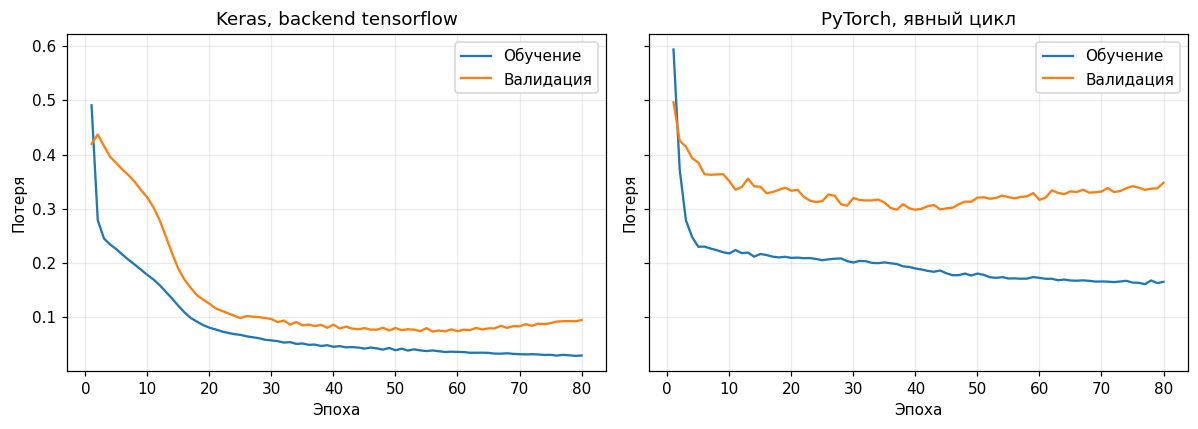

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].plot(keras_history_table.index, keras_history_table['loss'], label='Обучение')
axes[0].plot(keras_history_table.index, keras_history_table['val_loss'], label='Валидация')
axes[0].set_title(f'Keras, backend {keras.backend.backend()}')
axes[1].plot(torch_history_table.index, torch_history_table['loss'], label='Обучение')
axes[1].plot(torch_history_table.index, torch_history_table['val_loss'], label='Валидация')
axes[1].set_title('PyTorch, явный цикл')
for ax in axes:
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Потеря')
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()

**Разбор кода и графиков.**

- `plt.subplots(..., sharey=True)` создаёт две панели с общим вертикальным масштабом. `.index` таблиц содержит эпохи, квадратные скобки выбирают столбцы историй. `plot(...)` рисует линии с подписями `label`.
- `set_title(...)` именует опыт. Строка `f'...'` подставляет действительный результат `keras.backend.backend()` в заголовок.
- Цикл `for ax in axes` задаёт общий `set_xlabel`, `set_ylabel`, полупрозрачную `grid` и `legend`. `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

В обеих историях обучающая потеря обобщает пакеты в ходе эпохи, валидационная считается отдельно. Линии показывают работу заданных процессов. Отличия кривых не отменяют проверки восстановления, где сопоставлялись выходы одной модели до и после сохранения.

Восстановим сохранённую подготовку и получим ответы загруженных моделей для трёх новых исходных сочетаний сигналов. Порядок признаков оставим прежним. Правильные классы этих новых строк неизвестны, поэтому здесь показываются ответы моделей, а не метрики качества.

In [23]:
loaded_scaler = joblib.load(scaler_path)
new_raw_features = np.array([[0.0, 0.5], [1.0, -0.2], [1.5, 0.2]], dtype=np.float32)
new_prepared_features = loaded_scaler.transform(new_raw_features).astype(np.float32)
new_keras_logits = keras.ops.convert_to_numpy(loaded_keras_model(new_prepared_features, training=False))
new_keras_probabilities = keras.ops.convert_to_numpy(keras.ops.sigmoid(new_keras_logits)).ravel()
with torch.no_grad():
    new_torch_logits = loaded_torch_model(torch.from_numpy(new_prepared_features))
    new_torch_probabilities = torch.sigmoid(new_torch_logits).squeeze(1).numpy()

new_results = pd.DataFrame(new_raw_features, columns=feature_names)
new_results['Оценка класса 1: Keras'] = new_keras_probabilities
new_results['Оценка класса 1: PyTorch'] = new_torch_probabilities
display(new_results)

,Сигнал 1,Сигнал 2,Оценка класса 1: Keras,Оценка класса 1: PyTorch
0,0.0,0.5,0.9602,0.3007
1,1.0,-0.2,0.9999,1.0000
2,1.5,0.2,0.5807,0.5374


**Разбор кода и нового вывода.**

- `joblib.load(...)` восстанавливает созданный нами объект подготовки. `np.array(..., dtype=np.float32)` задаёт три исходные строки с двумя признаками. `.transform(...)` применяет сохранённое правило; нового `fit` нет. `.astype(...)` согласует тип результата.
- `loaded_keras_model(..., training=False)` напрямую получает логиты новых строк в режиме получения ответа; `keras.ops.convert_to_numpy(...)` возвращает их в NumPy. Далее `keras.ops.sigmoid(...)` преобразует логиты в оценки класса 1, а второй `convert_to_numpy(...)` получает массив для таблицы. `.ravel()` убирает единичный столбец.
- В `torch.no_grad()` `torch.from_numpy(...)` создаёт тензор подготовленных данных, `loaded_torch_model(...)` получает логиты. `torch.sigmoid`, `.squeeze(1)` и `.numpy()` готовят оценки. Модель уже переведена в `eval` при восстановлении.
- `pd.DataFrame(...)` показывает исходные поля в нужном порядке; присваивания добавляют два столбца ответов, `display(...)` выводит результат.

Сохранённые сеть и подготовка используются совместно. Различия оценок двух моделей допустимы: это не проверка их числового равенства друг другу. Выше подтверждалось воспроизведение **каждой собственной** модели при загрузке.

У первого нового сочетания оценка класса 1 около 0,9602 у Keras с TensorFlow и 0,3007 у PyTorch. Предпочтения моделей различаются. Без правильного ответа новой строки из этой разницы нельзя определить, какой результат верен; здесь демонстрируется применение восстановленных объектов.

Зафиксируем выполнение разделов и версии в небольшом текстовом файле. Итоговая таблица подтверждает завершение примеров, а описание сохраняет backend TensorFlow, версии библиотек, порядок признаков и имена файлов моделей. Это позволяет связать сохранённые результаты с конкретной средой запуска.

In [24]:
execution_status = pd.DataFrame({
    'Раздел': ['Keras', 'PyTorch', 'TensorFlow: собственные примеры'],
    'Статус': ['Выполнен', 'Выполнен', 'Выполнен' if tensorflow_examples_executed else 'Не завершён'],
})
display(execution_status)
result_metadata = {
    'порядок_признаков': feature_names,
    'backend_keras': keras.backend.backend(),
    'версии': {
        'python': sys.version.split()[0],
        'keras': keras.__version__,
        'torch': torch.__version__,
        'tensorflow': tf.__version__,
        'scikit_learn': sklearn.__version__,
    },
    'tensorflow_выполнен': tensorflow_examples_executed,
    'файлы': {
        'keras': keras_path.name,
        'pytorch': torch_path.name,
        'подготовка': scaler_path.name,
    },
}
metadata_path = artifact_dir / 'описание_результатов.json'
metadata_path.write_text(json.dumps(result_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Описание результатов:', metadata_path.resolve())

,Раздел,Статус
0,Keras,Выполнен
1,PyTorch,Выполнен
2,TensorFlow: собственные примеры,Выполнен


Описание результатов: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\12_результаты_фреймворки\описание_результатов.json


**Разбор кода и статуса.**

- `pd.DataFrame({...})` создаёт таблицу из словаря списков. Выражение `'Выполнен' if tensorflow_examples_executed else 'Не завершён'` выбирает текст по логическому флагу из примера TensorFlow. `display(...)` показывает сводку.
- `result_metadata` — словарь с вложенными словарями версий и имён файлов. `keras.backend.backend()` фиксирует текущий backend. `.__version__` читает версии, а `tensorflow_examples_executed` сохраняет факт завершения примеров как логическое значение.
- `sys.version.split()[0]` берёт краткую версию Python: `split()` делит строку сведений на фрагменты, `[0]` выбирает первый. Атрибут `.name` у пути даёт имя файла без каталога.
- `json.dumps(..., ensure_ascii=False, indent=2)` создаёт читаемый JSON с русскими символами и отступами. `Path.write_text(..., encoding='utf-8')` записывает его; `.resolve()` получает абсолютный путь, `print(...)` выводит его.

В сохранённом запуске все три раздела выполнены. В `описание_результатов.json` записаны `backend_keras: "tensorflow"`, версия TensorFlow 2.21.0 и `tensorflow_выполнен: true`. Это результат данного запуска; при повторном выполнении файл обновляется фактическими сведениями среды.

## 7. Что читать в примере фреймворка

Сначала важно установить, где находятся данные и какая у них форма, затем — что возвращает последний слой. После этого можно проследить настройки обучения, цикл, проверку и получение ответа. Название метода само по себе не определяет смысл выходных чисел.

Keras организует много стандартных действий через `compile`, `fit`, `evaluate`, `predict`. PyTorch в показанном стиле делает структуру и цикл явными через `nn.Module`, `DataLoader` и код программы. TensorFlow даёт собственные тензоры, переменные и запись вычислений, а при выбранном TensorFlow backend предоставляет вычислительную основу для того же высокоуровневого Keras.

Для воспроизведения результата нужны не только веса: важны структура, подготовка, порядок полей, версии и выбранный backend. В этой теме показано сохранение маленьких учебных моделей. Развёртывание сервисов, мониторинг и MLOps относятся к следующим разделам курса.

### Официальные справочные страницы

Дополнительные материалы: [установка TensorFlow](https://www.tensorflow.org/install/pip), [основные вычисления TensorFlow и GradientTape](https://www.tensorflow.org/guide/autodiff), [начало работы с Keras 3 и выбор backend](https://keras.io/getting_started/), [встроенные методы обучения Keras](https://keras.io/guides/training_with_built_in_methods/), [сохранение Keras](https://keras.io/guides/serialization_and_saving/), [модули PyTorch 2.11](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Module.html), [работа с данными PyTorch 2.11](https://docs.pytorch.org/docs/2.11/data.html), [сохранение и загрузка PyTorch 2.11](https://docs.pytorch.org/docs/2.11/notes/serialization.html). Ссылки справочные; для всех примеров с установленными TensorFlow, Keras и PyTorch интернет не требуется.